# Subroutine 3

### installing necessary packages

In [30]:
! pip install numpy
! pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


### Defining Function for matrix vector multiplication (banded unit lower triangular)

In [31]:
def unit_lower_matvec_banded(B, v, n):
    """
    Compute w = L v, where L is unit lower triangular and banded
    (nonzeros only on the two subdiagonals), stored in the 2-D array B with 2 columns:
        B[i-1][1] = L[i][i-1]   (first subdiagonal),   i = 1..n-1
        B[i-1][0] = L[i][i-2]   (second subdiagonal),  i = 2..n-1
    Indices are 0-based; B[0][0] is the unused slot.
    B : 2-D array with at least n rows and 2 columns
    v : 1-D array of length n
    """
    w = [0.0] * n

    # Diagonal of L is 1, so w starts as v
    for i in range(n):
        w[i] = v[i]

    # Long vector 1: first subdiagonal times v shifted by 1 (length n-1)
    for i in range(1, n):
        w[i] = w[i] + B[i-1][1] * v[i-1]

    # Long vector 2: second subdiagonal times v shifted by 2 (length n-2)
    for i in range(2, n):
        w[i] = w[i] + B[i-1][0] * v[i-2]

    return w

### Testing using the known result (Basic 5 by 5)

In [32]:
# L = [[1, 0, 0, 0, 0],
#      [2, 1, 0, 0, 0],
#      [3, 4, 1, 0, 0],
#      [0, 5, 6, 1, 0],
#      [0, 0, 7, 8, 1]]

# Banded storage: column 0 = second subdiagonal, column 1 = first subdiagonal
# (B[0][0] is the unused slot; None would raise an error if the routine ever read it)
B = [[None, 2],
     [3,    4],
     [5,    6],
     [7,    8]]

v = [1, 1, 1, 1, 1]

w = unit_lower_matvec_banded(B, v, 5)
print("w =", w)
w_expected = [1, 3, 8, 12, 16]  # expected (row sums, worked out by hand)

if w == w_expected:
    print("yeeee, it works!")
else:
    print("oh no, it failed:", w, "!=", w_expected)

w = [1, 3, 8, 12, 16]
yeeee, it works!


### Generating random banded matrix(L), vector(v) and comparing result

In [33]:
import numpy as np
n = int(input("Enter n: "))

rng = np.random.default_rng(seed=42)  # for reproducibility

# Full banded unit lower triangular matrix (only 2 subdiagonals nonzero, ones on the diagonal)
L = np.eye(n) + np.tril(np.triu(rng.random((n, n)), -2), -1)

# Banded storage: n rows x 2 columns (2n locations), NaN in the unused slots
B = np.full((n, 2), np.nan)
for i in range(1, n):
    B[i-1][1] = L[i][i-1]        # first subdiagonal
for i in range(2, n):
    B[i-1][0] = L[i][i-2]        # second subdiagonal

# Random vector
v = rng.random(n)

w_comp = np.array(unit_lower_matvec_banded(B.tolist(), v.tolist(), n))   # our routine (uses B, not L)
w_true = L @ v                                                           # NumPy

abs_err = np.linalg.norm(w_comp - w_true)
rel_err = abs_err / np.linalg.norm(w_true)

#print("L (full matrix) =\n", L)
#print("\nBanded storage B (col 0 = 2nd subdiagonal, col 1 = 1st subdiagonal) =\n", B)
#print("\nv =", v)
#print("\nw computed  =", w_comp)
#print("w true =", w_true)
print("absolute error =", abs_err)
print("relative error =", rel_err)

absolute error = 3.0710073827117147e-15
relative error = 8.83156835778939e-17


### Error analysis over many sizes (L2 and L-inf relative error)

In [34]:
step = 10
n_max = n
n_list = list(range(3, n_max + 3, step))
K = len(n_list)

rng = np.random.default_rng(42)   # reproducible
ntrials = 20

def rel_err(d, w, p):
    """Relative error ||d|| / ||w|| in the p-norm (falls back to absolute if ||w|| = 0)."""
    a = np.linalg.norm(d, p)
    b = np.linalg.norm(w, p)
    return a / b if b > 0 else a

max_rel2 = np.zeros(K);  mean_rel2 = np.zeros(K)     # L2
max_reli = np.zeros(K);  mean_reli = np.zeros(K)     # L-inf
rel2_all, reli_all = [], []                          # per-n distributions

for k, size in enumerate(n_list):

    r2 = np.zeros(ntrials)
    ri = np.zeros(ntrials)

    for t in range(ntrials):
        # banded unit lower triangular L
        L = np.eye(size) + np.tril(np.triu(rng.standard_normal((size, size)), -2), -1)

        # banded storage (NaN in unused slots)
        B = np.full((size, 2), np.nan)
        for i in range(1, size):
            B[i-1][1] = L[i][i-1]
        for i in range(2, size):
            B[i-1][0] = L[i][i-2]

        # random v, normalized
        v = rng.standard_normal(size)
        v = v / np.linalg.norm(v)

        w_true = L @ v
        w_comp = np.array(unit_lower_matvec_banded(B.tolist(), v.tolist(), size))   # our routine 3

        d = w_comp - w_true
        r2[t] = rel_err(d, w_true, 2)
        ri[t] = rel_err(d, w_true, np.inf)

    rel2_all.append(r2);  reli_all.append(ri)
    max_rel2[k], mean_rel2[k] = r2.max(), r2.mean()
    max_reli[k], mean_reli[k] = ri.max(), ri.mean()

all_rel2 = np.concatenate(rel2_all)
all_reli = np.concatenate(reli_all)

print(f"{'Summary statistics':26s}{'L2':>12s}{'L-inf':>12s}")
print(f"{'Mean of mean rel errors':26s}{mean_rel2.mean():12.3e}{mean_reli.mean():12.3e}")
print(f"{'Max of max rel errors':26s}{max_rel2.max():12.3e}{max_reli.max():12.3e}")
print(f"{'All-tests rel error mean':26s}{all_rel2.mean():12.3e}{all_reli.mean():12.3e}")
print(f"{'All-tests rel error var':26s}{all_rel2.var(ddof=1):12.3e}{all_reli.var(ddof=1):12.3e}")

Summary statistics                  L2       L-inf
Mean of mean rel errors      8.214e-17   1.240e-16
Max of max rel errors        1.559e-16   2.347e-16
All-tests rel error mean     8.214e-17   1.240e-16
All-tests rel error var      1.406e-34   1.510e-33


### Plot: relative error vs n

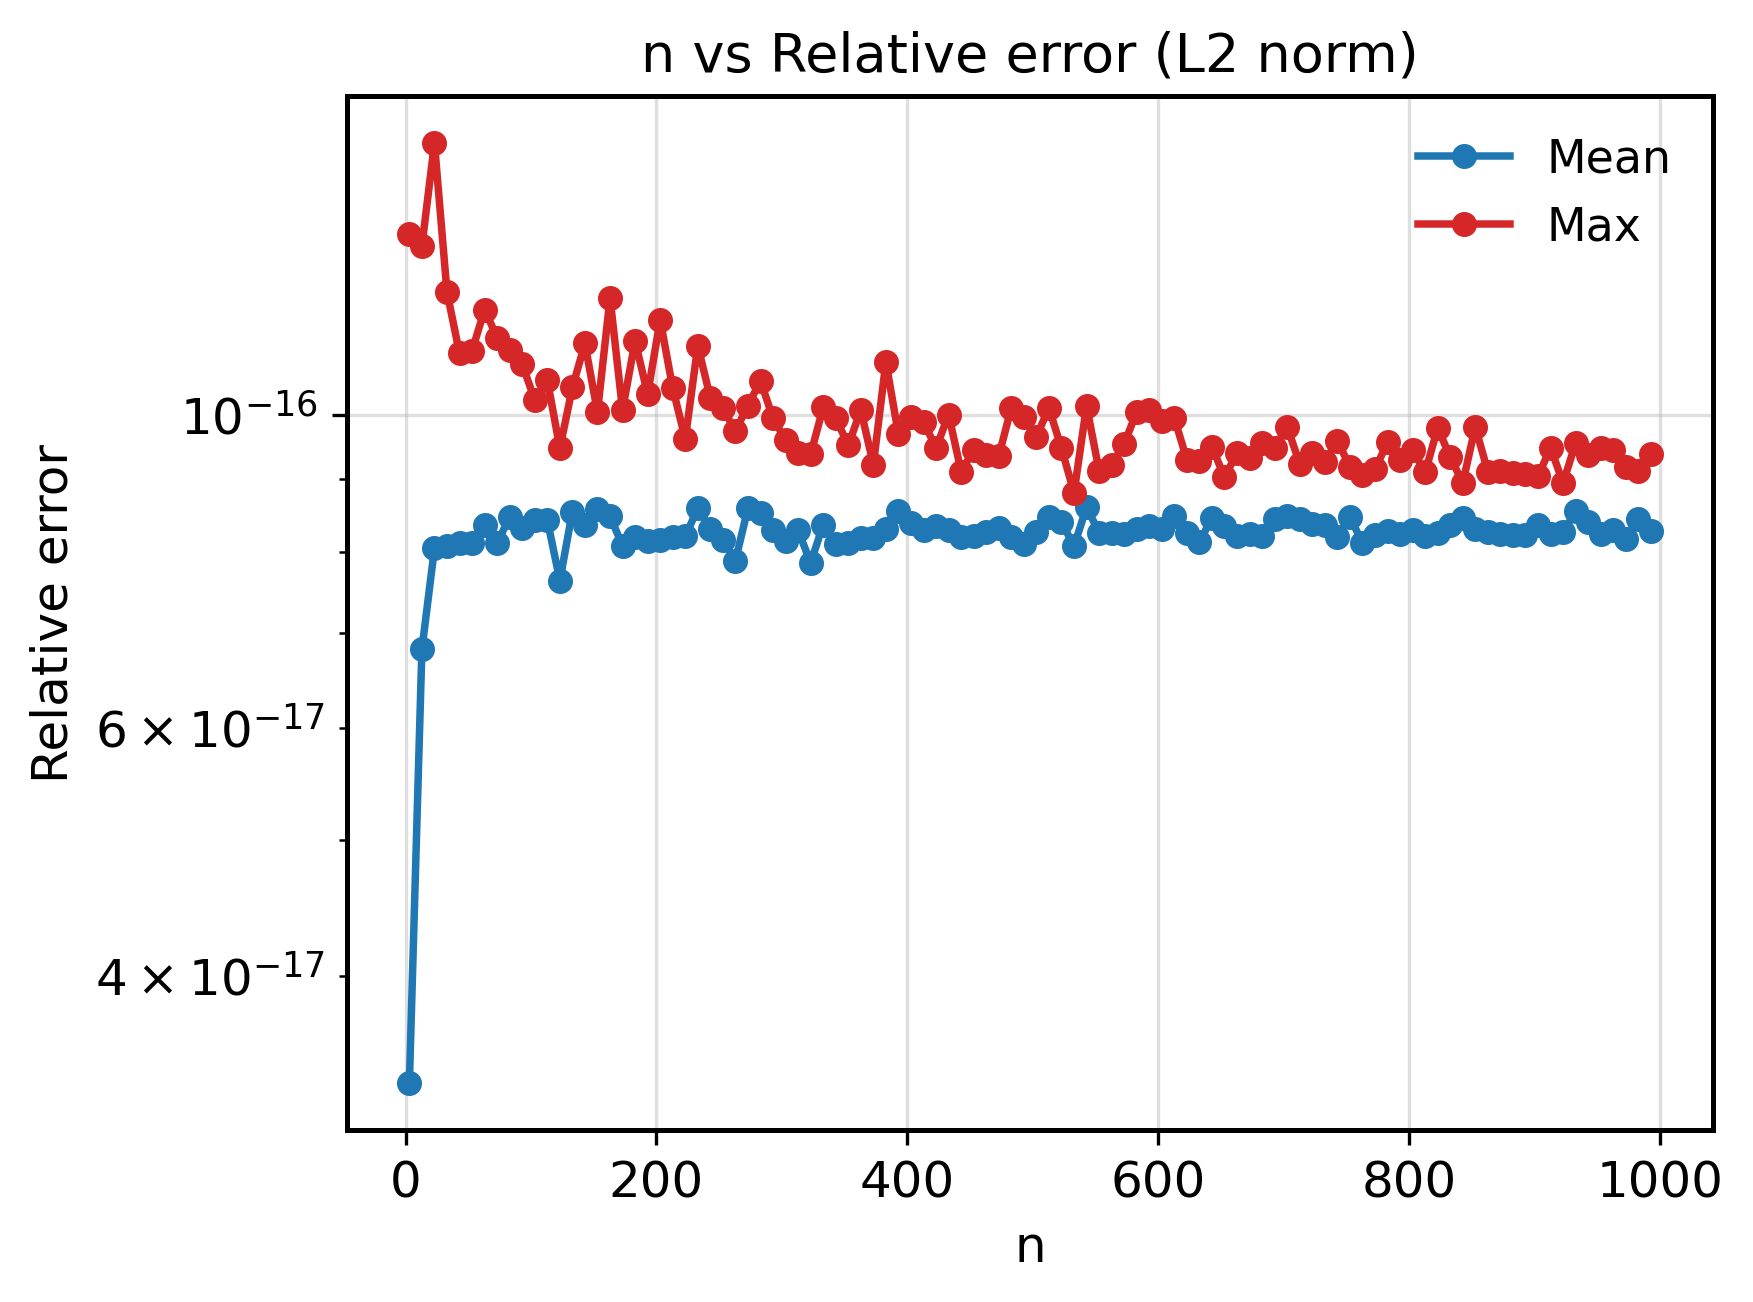

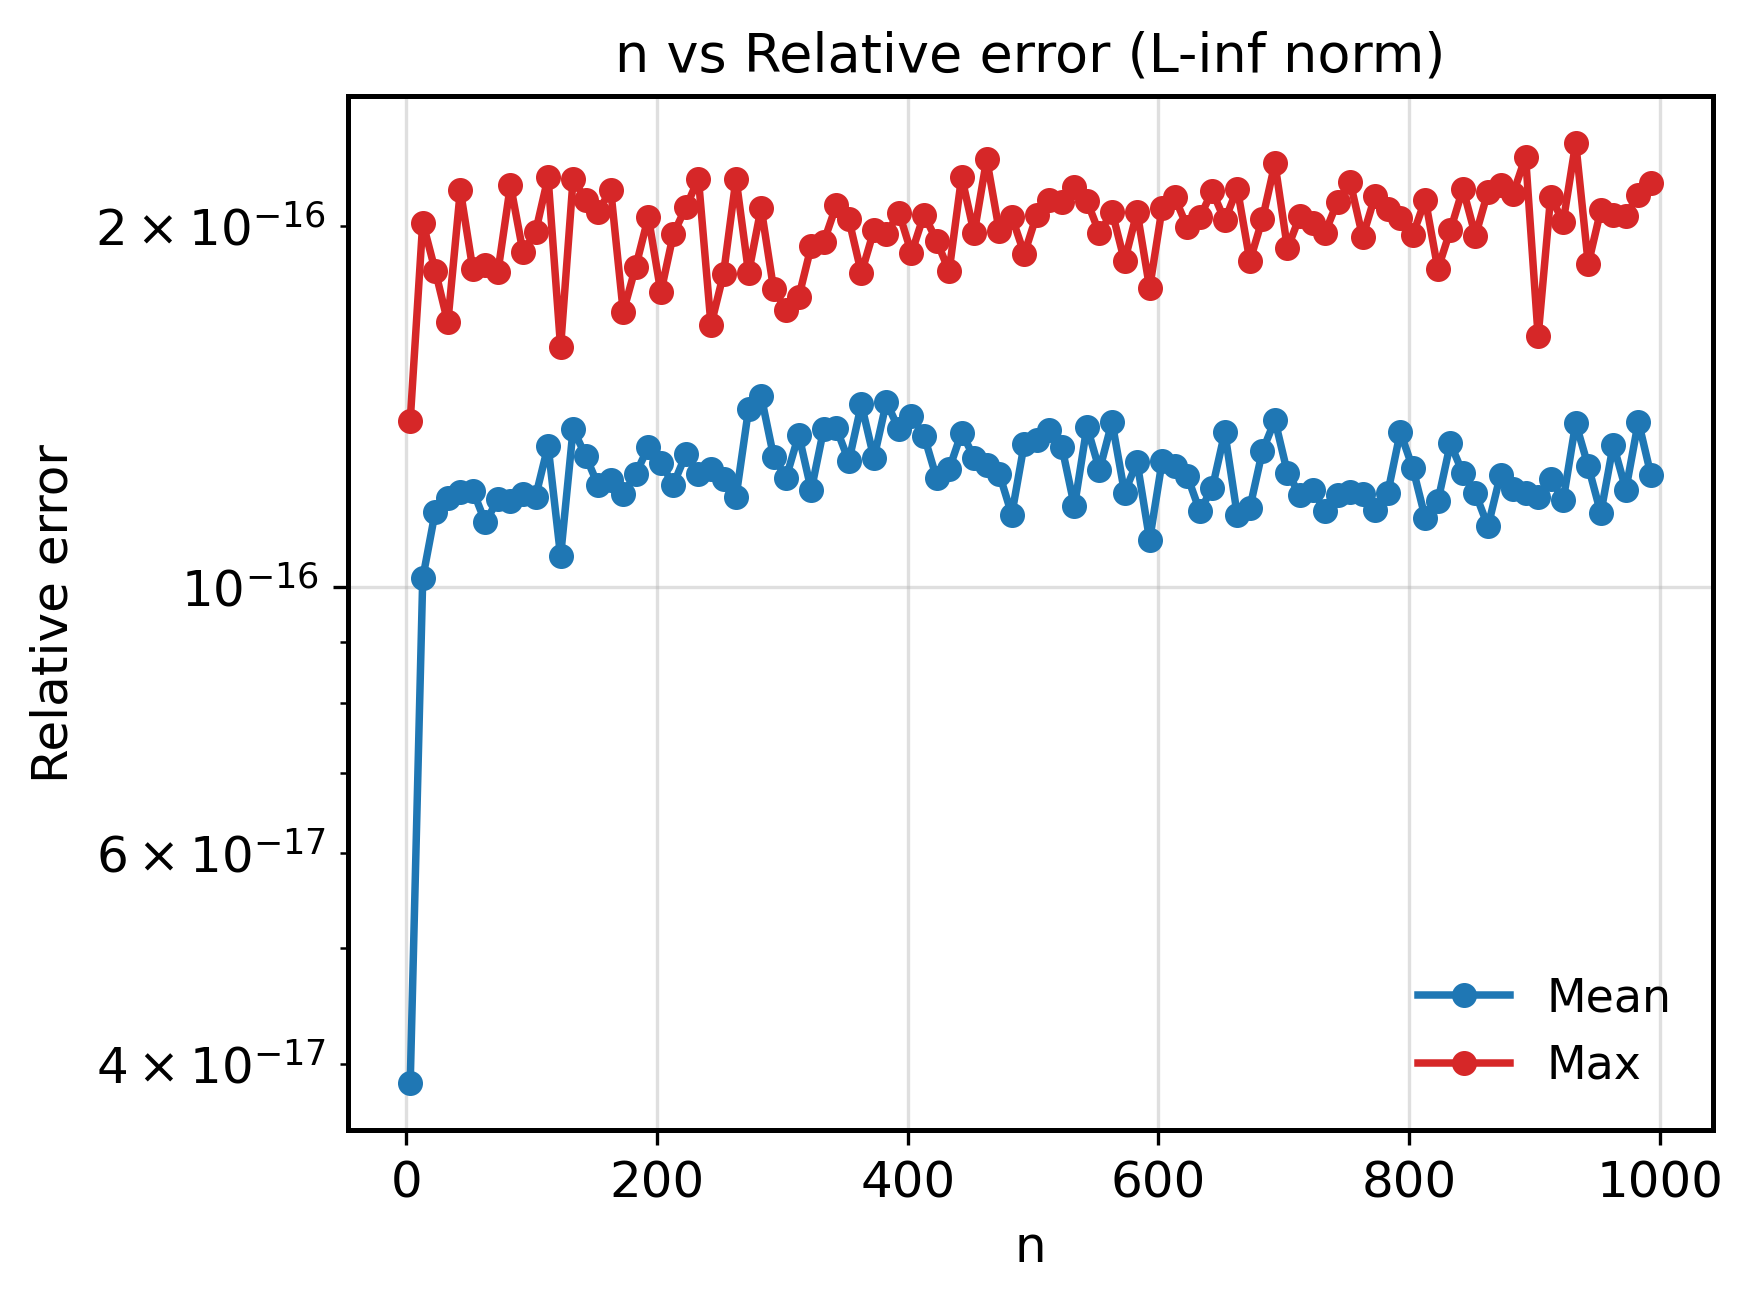

In [35]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "axes.spines.top": True,      # full border on all four sides
    "axes.spines.right": True,
    "axes.linewidth": 1.2,        # slightly thicker border
})

plots = [(mean_rel2, max_rel2, "L2 norm",    "L2"),
         (mean_reli, max_reli, "L-inf norm", "Linf")]

for m, M, name, tag in plots:
    fig, a = plt.subplots(figsize=(6, 4.5))      # one figure per plot

    a.semilogy(n_list, m, "-o", color="#1f77b4", lw=1.8, ms=5, label="Mean")
    a.semilogy(n_list, M, "-o", color="#d62728", lw=1.8, ms=5, label="Max")
    #a.axhline(np.finfo(float).eps, color="gray", ls=":", label="machine epsilon")

    a.set_xlabel("n")
    a.set_ylabel("Relative error")
    a.set_title(f"n vs Relative error ({name})")
    a.grid(True, which="major", alpha=0.4)
    a.legend(frameon=False, loc="best")

    plt.tight_layout()
    plt.savefig(f"subroutine3_error_{tag}_n{n_max}.pdf", bbox_inches="tight")   # vector PDF
    plt.savefig(f"subroutine3_error_{tag}_n{n_max}.png", dpi=300, bbox_inches="tight")
    plt.show()

### Histograms

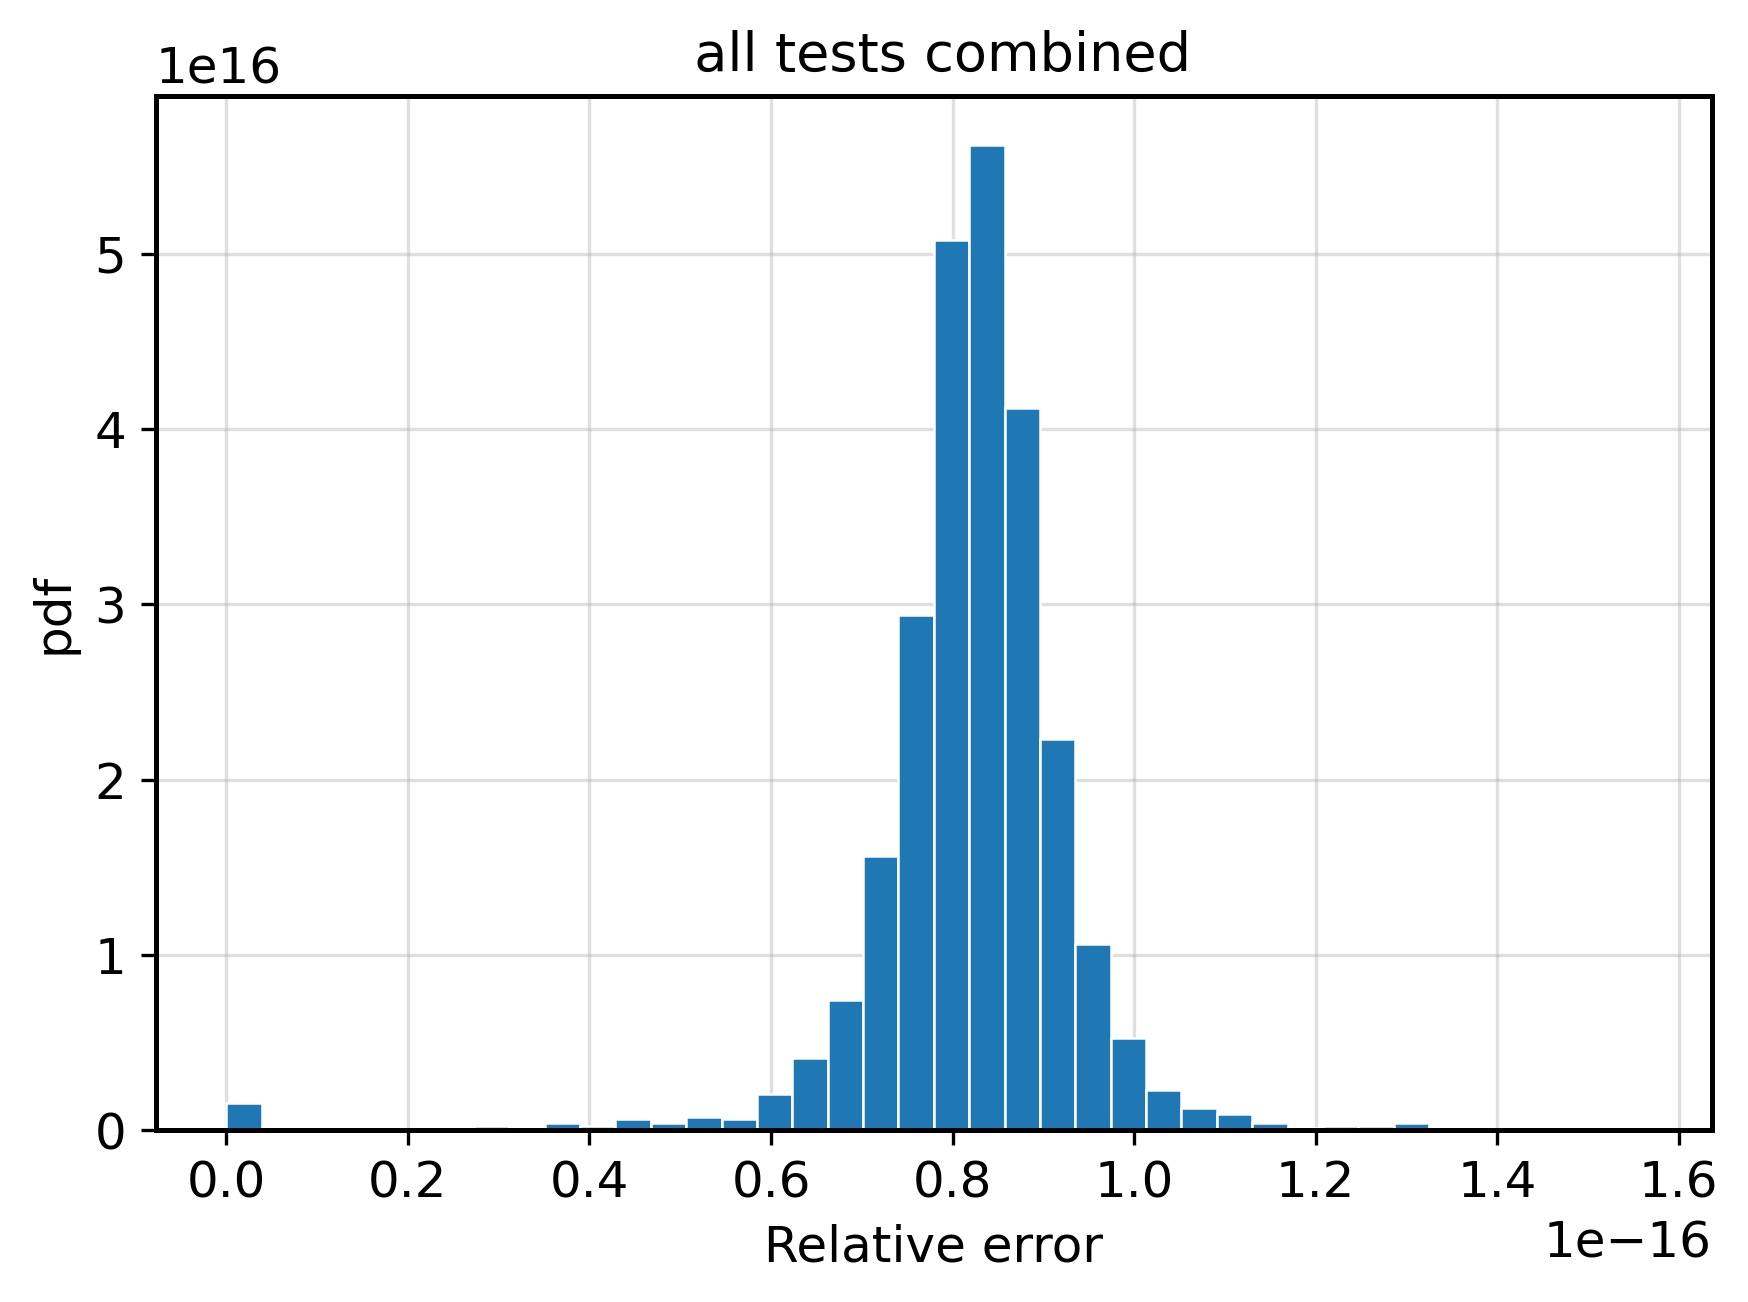

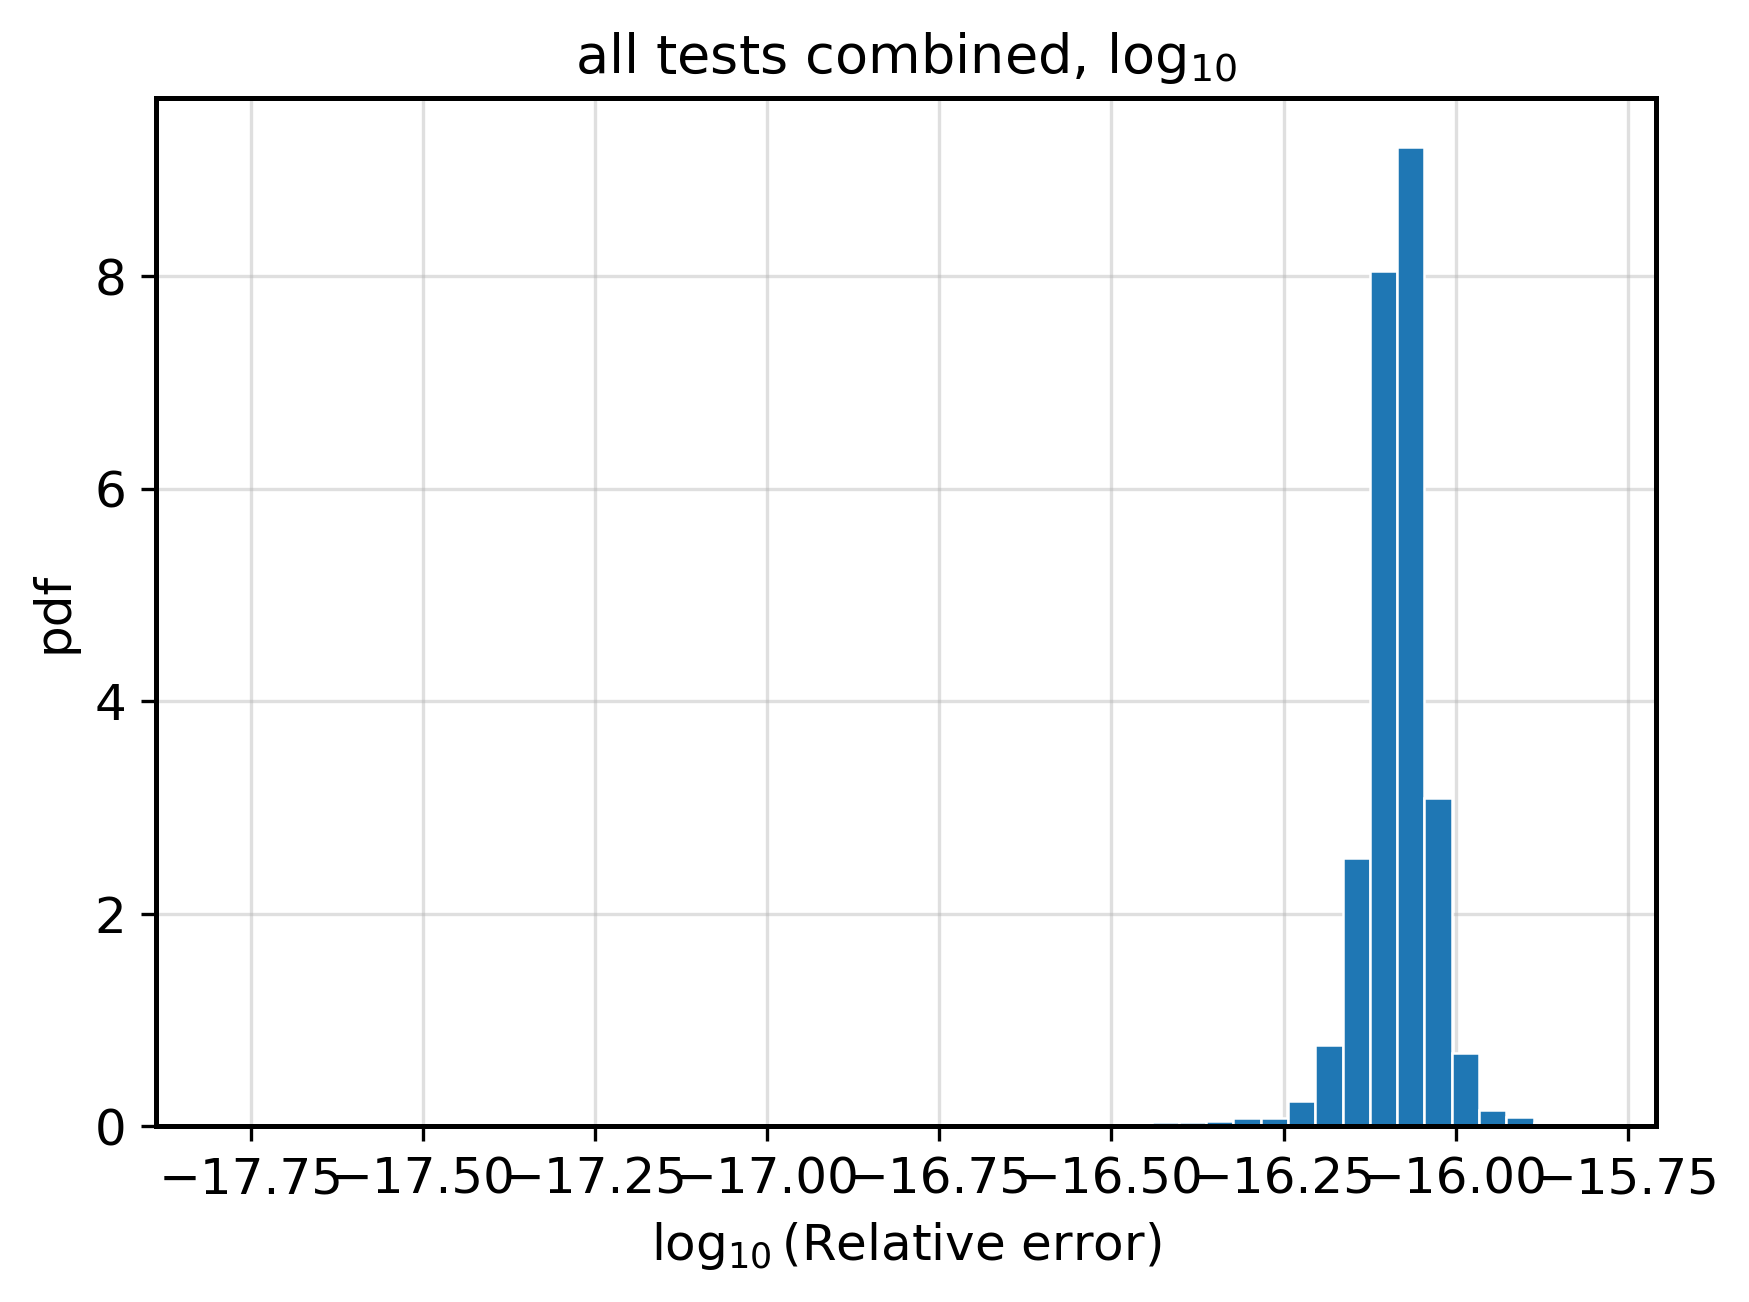

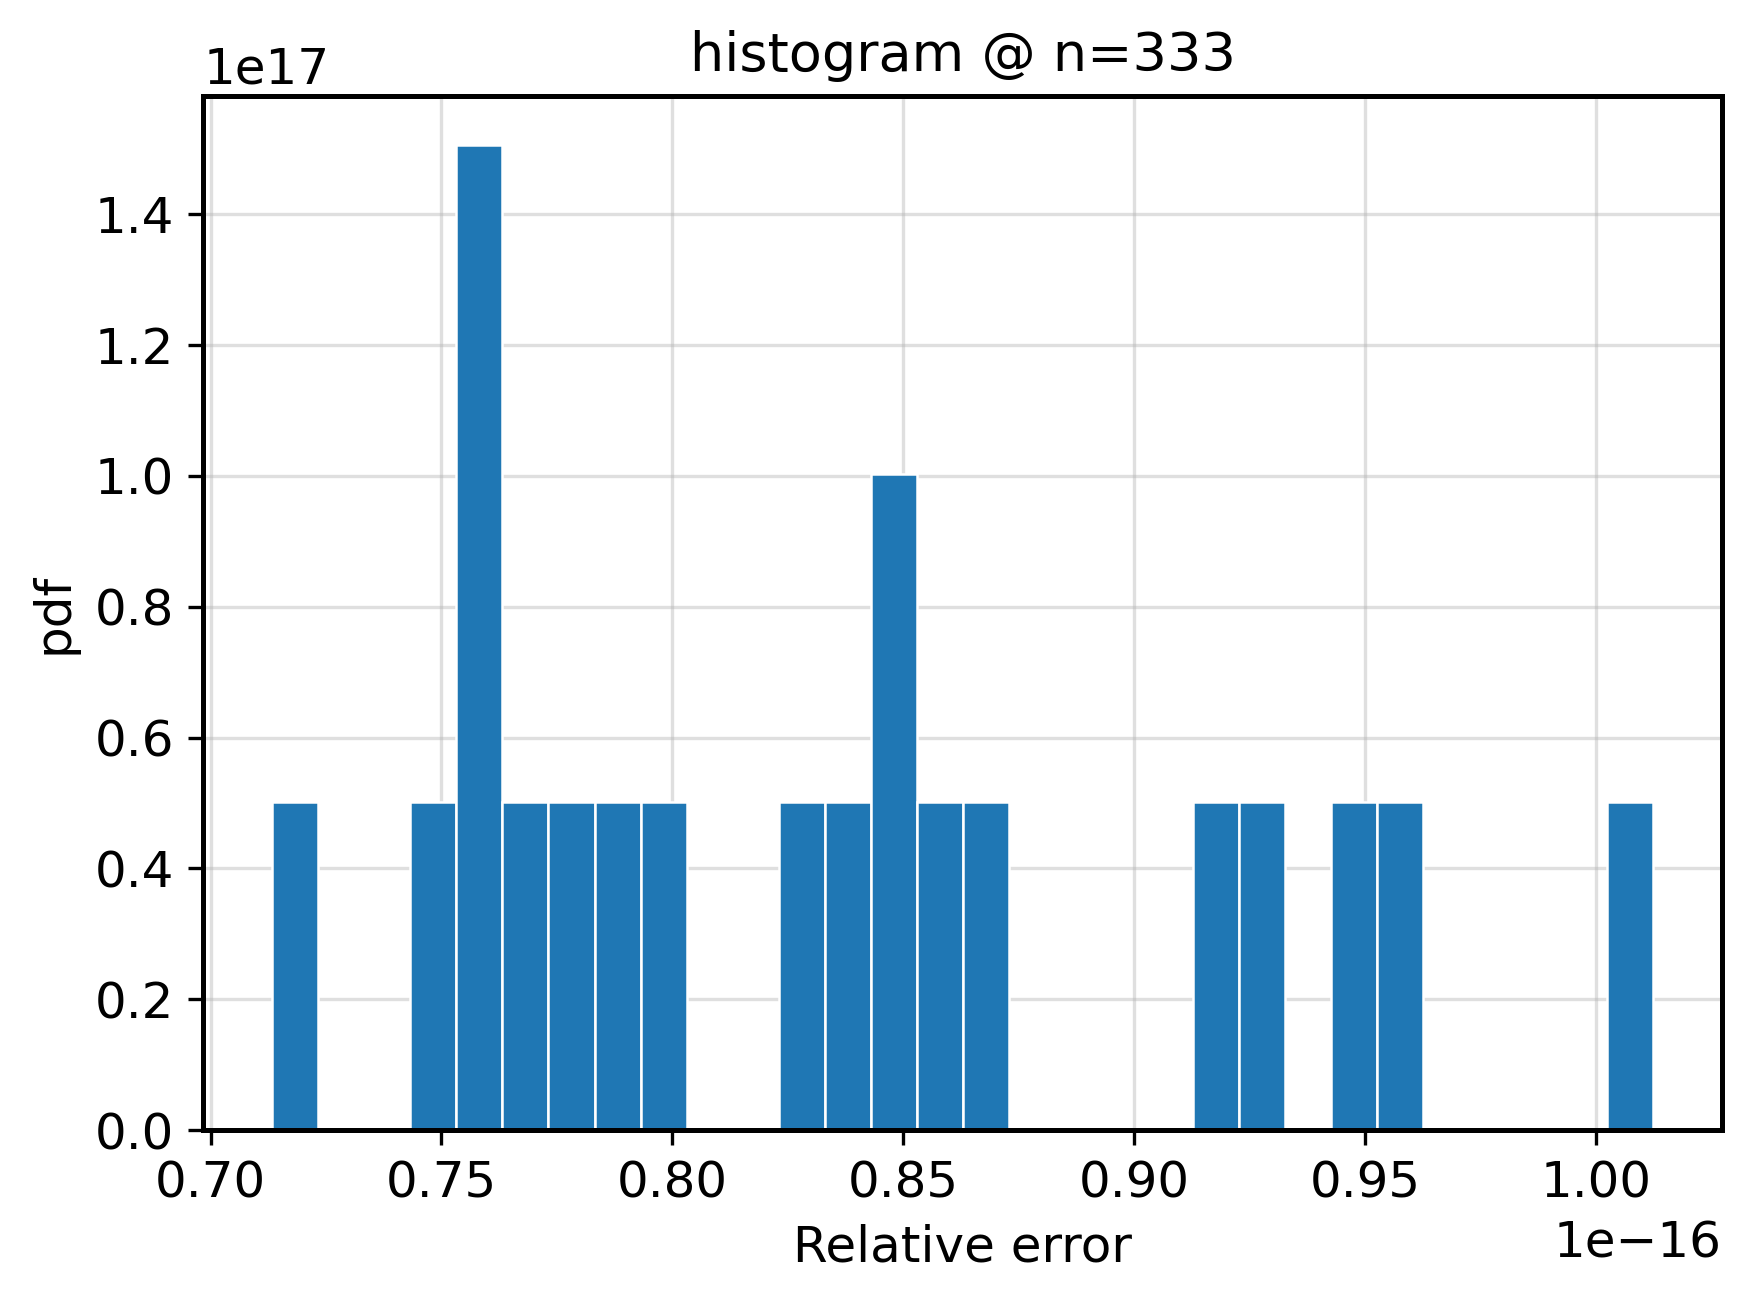

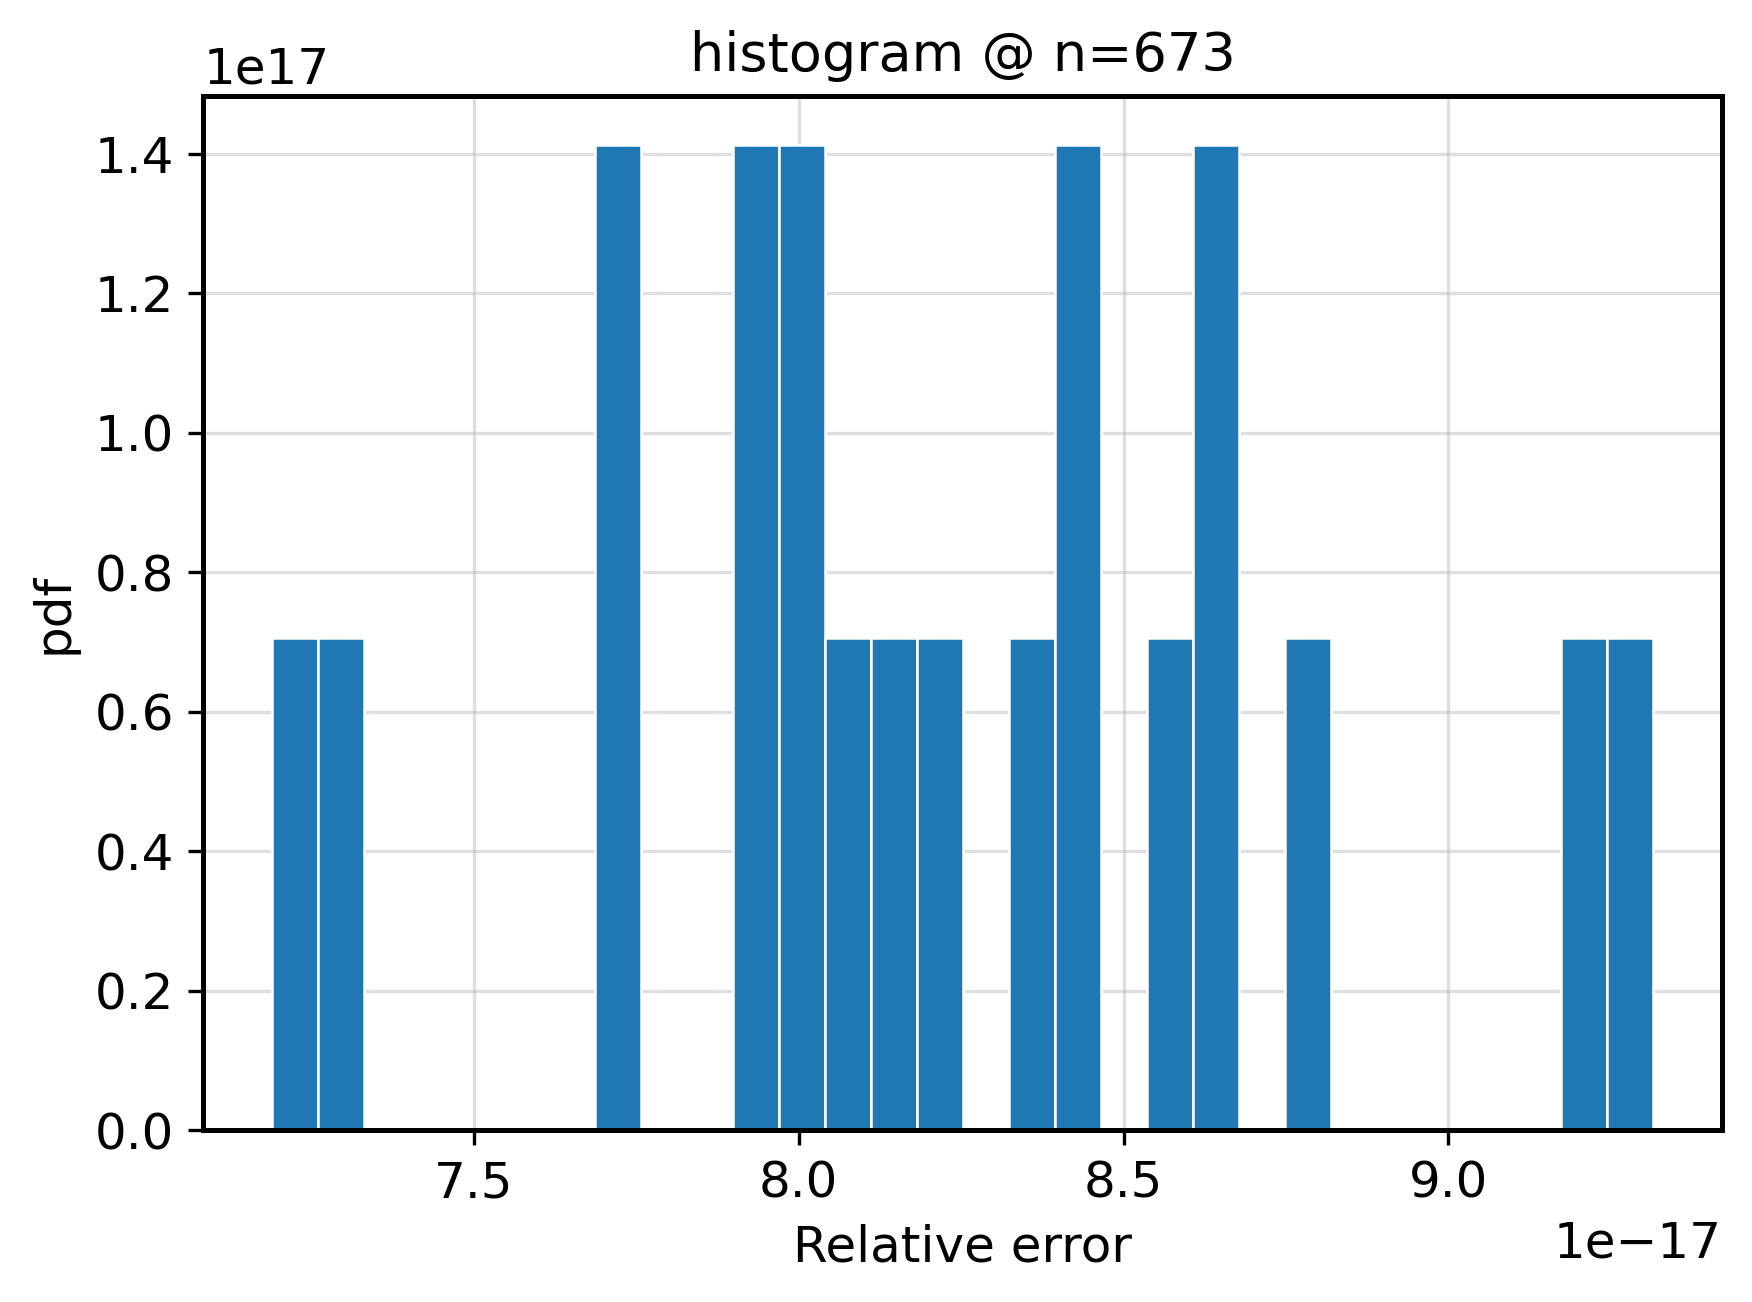

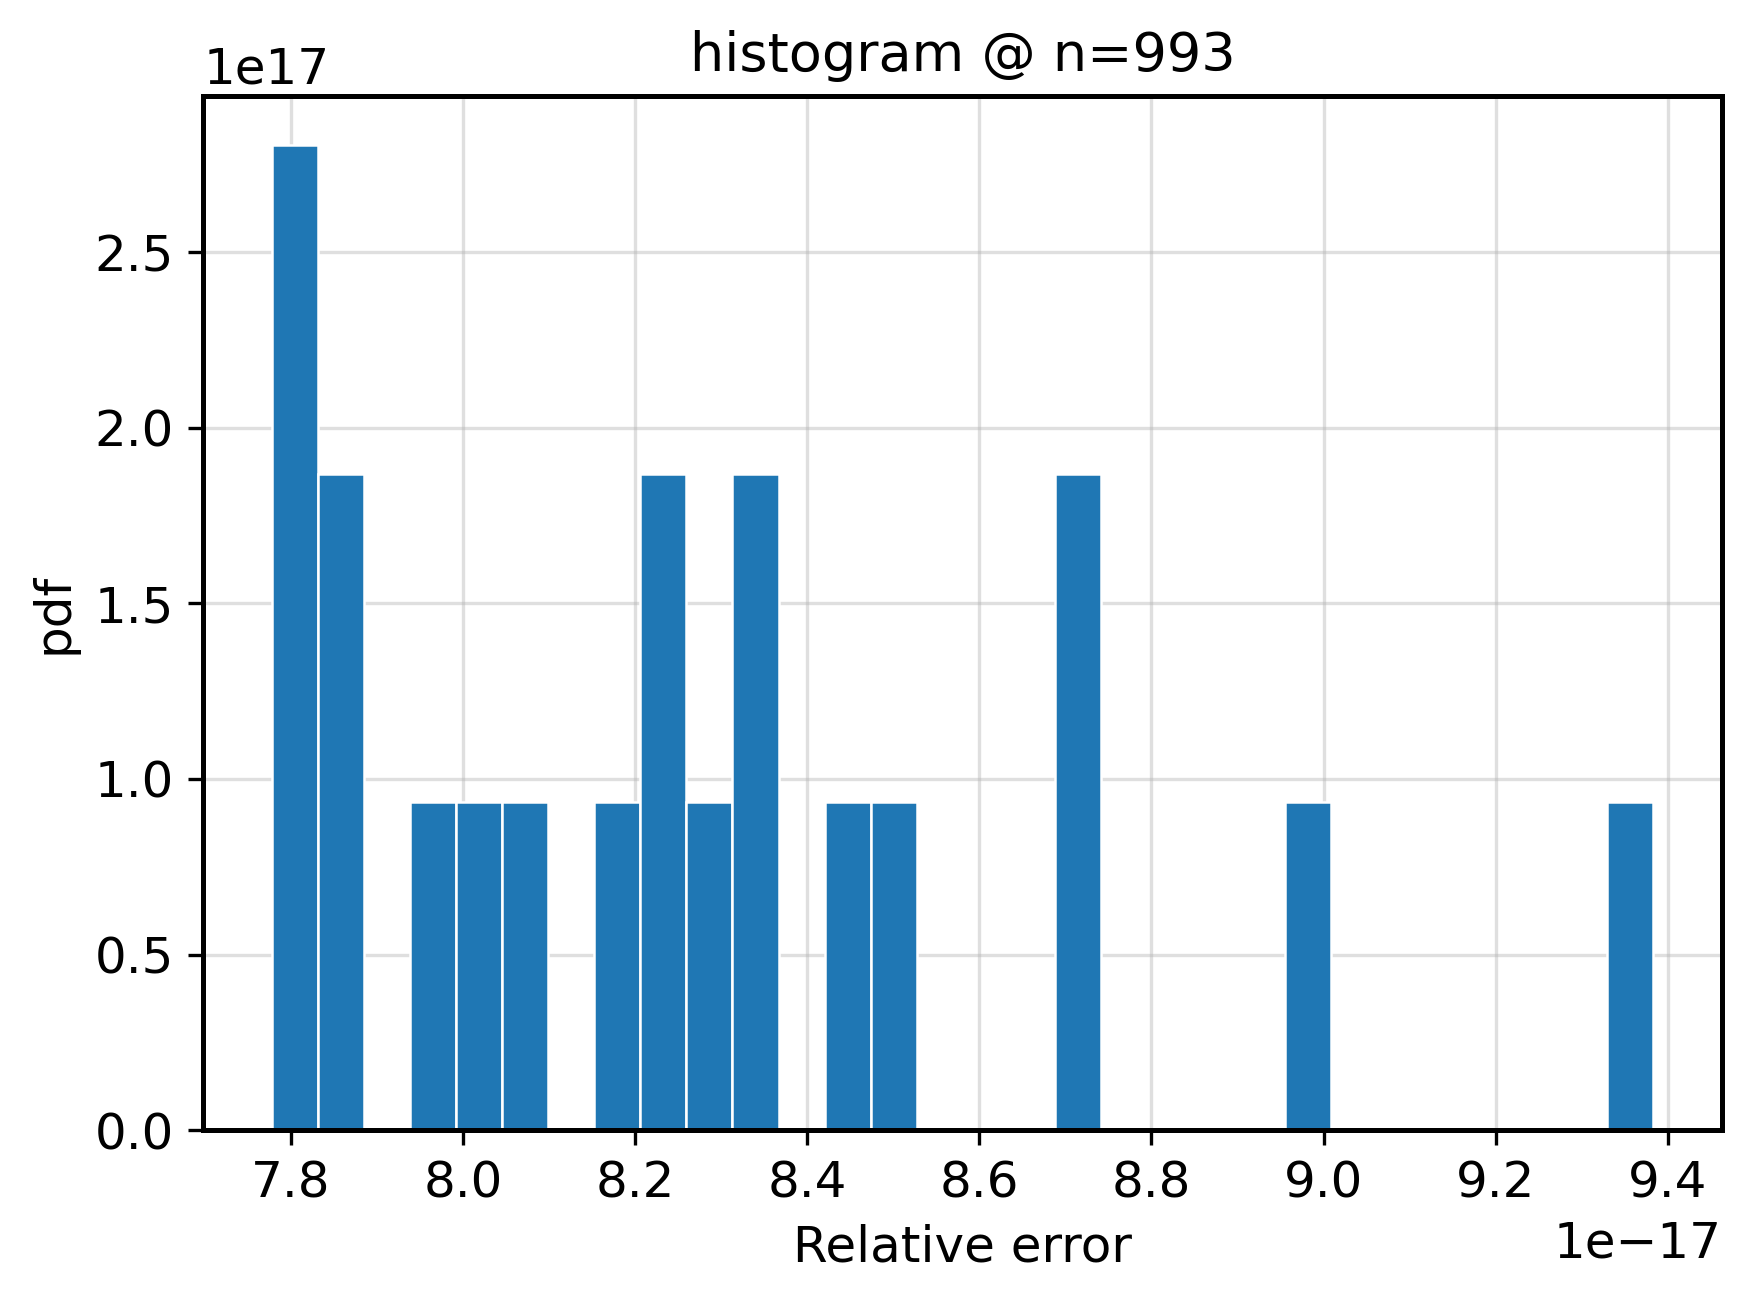

In [36]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.linewidth": 1.2,
})

def save_hist(data, xlabel, title, fname, bins):
    """One histogram per figure, same style as the line plots."""
    fig, a = plt.subplots(figsize=(6, 4.5))
    a.hist(data, bins=bins, density=True,
           color="#1f77b4", edgecolor="white", linewidth=0.6)
    a.set_xlabel(xlabel)
    a.set_ylabel("pdf")
    a.set_title(title)
    a.grid(True, which="major", alpha=0.4)
    a.set_axisbelow(True)                     # grid behind the bars
    plt.tight_layout()
    plt.savefig(f"{fname}.pdf", bbox_inches="tight")             # vector PDF
    plt.savefig(f"{fname}.png", dpi=300, bbox_inches="tight")
    plt.show()

# Combined, across all sizes
save_hist(all_rel2, "Relative error",
          " all tests combined",
          f"subroutine3_hist_all_n{n_max}", bins=40)

pos = all_rel2[all_rel2 > 0]
save_hist(np.log10(pos), r"$\log_{10}$(Relative error)",
          r"all tests combined, $\log_{10}$",
          f"subroutine3_hist_all_log10_n{n_max}", bins=50)

# Per-n, at about n_max/3, 2*n_max/3 and n_max (never n = 1)
rep_ns = sorted(set(max(2, round(x)) for x in [n_max/3, 2*n_max/3, n_max]))
rep_idx = sorted(set(next((i for i, m in enumerate(n_list) if m >= r), K - 1) for r in rep_ns))

for j, i in enumerate(rep_idx, start=1):
    save_hist(rel2_all[i], "Relative error",
              f"histogram @ n={n_list[i]}",
              f"subroutine3_pern_n{n_max}_{j}", bins=30)